# Placement Predictor — Preprocessing & EDA


## 1. Upload the dataset files

In [3]:
from google.colab import files
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
required_files = {"train.csv", "validation.csv", "test.csv"}
missing_files = required_files - set(uploaded.keys())
if missing_files:
    raise ValueError(f"Please upload: {', '.join(sorted(missing_files))}")

train_df = pd.read_csv(io.BytesIO(uploaded["train.csv"]))
validation_df = pd.read_csv(io.BytesIO(uploaded["validation.csv"]))
test_df = pd.read_csv(io.BytesIO(uploaded["test.csv"]))

TARGET = "PlacementStatus"
print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)
display(train_df.head())


Saving test.csv to test.csv
Saving train.csv to train.csv
Saving validation.csv to validation.csv
Train: (7225, 11)
Validation: (1275, 11)
Test: (1500, 11)


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


## 2. Inspect columns, data types, and descriptive statistics

In [4]:
print("Columns:", train_df.columns.tolist())
train_df.info()
display(train_df.describe(include="all").T)
print("Do all splits have matching columns?",
      set(train_df.columns) == set(validation_df.columns) == set(test_df.columns))


Columns: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7225 entries, 0 to 7224
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CGPA                       7225 non-null   float64
 1   Internships                7225 non-null   int64  
 2   Projects                   7225 non-null   int64  
 3   Workshops/Certifications   7225 non-null   int64  
 4   AptitudeTestScore          7225 non-null   int64  
 5   SoftSkillsRating           7225 non-null   float64
 6   ExtracurricularActivities  7225 non-null   object 
 7   PlacementTraining          7225 non-null   object 
 8   SSC_Marks                  7225 non-null   int64  
 9   HSC_Marks                  7225 non-null   int64  
 10  Placeme

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CGPA,7225.0,NaN,NaN,NaN,7.701426,0.637035,6.5,7.4,7.7,8.2,9.1
Internships,7225.0,NaN,NaN,NaN,1.048997,0.666042,0.0,1.0,1.0,1.0,2.0
Projects,7225.0,NaN,NaN,NaN,2.02699,0.86808,0.0,1.0,2.0,3.0,3.0
Workshops/Certifications,7225.0,NaN,NaN,NaN,1.017993,0.904007,0.0,0.0,1.0,2.0,3.0
AptitudeTestScore,7225.0,NaN,NaN,NaN,79.471557,8.157964,60.0,73.0,80.0,87.0,90.0
SoftSkillsRating,7225.0,NaN,NaN,NaN,4.325522,0.40999,3.0,4.0,4.4,4.7,4.8
ExtracurricularActivities,7225,2,Yes,4245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PlacementTraining,7225,2,Yes,5270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SSC_Marks,7225.0,NaN,NaN,NaN,69.187543,10.445257,55.0,59.0,70.0,78.0,90.0
HSC_Marks,7225.0,NaN,NaN,NaN,74.460623,8.905815,57.0,67.0,73.0,83.0,88.0


Do all splits have matching columns? True


## 3. Check missing values and duplicate rows

In [5]:
print("Missing values by column:")
display(train_df.isnull().sum().to_frame("Missing values"))
print("Total missing values:",
      {"train": int(train_df.isnull().sum().sum()),
       "validation": int(validation_df.isnull().sum().sum()),
       "test": int(test_df.isnull().sum().sum())})
print("Duplicate rows:",
      {"train": int(train_df.duplicated().sum()),
       "validation": int(validation_df.duplicated().sum()),
       "test": int(test_df.duplicated().sum())})


Missing values by column:


,Missing values
CGPA,0
Internships,0
Projects,0
Workshops/Certifications,0
AptitudeTestScore,0
SoftSkillsRating,0
ExtracurricularActivities,0
PlacementTraining,0
SSC_Marks,0
HSC_Marks,0


Total missing values: {'train': 0, 'validation': 0, 'test': 0}
Duplicate rows: {'train': 43, 'validation': 0, 'test': 0}


## 4. Explore placement status

,Number of records
PlacementStatus,
NotPlaced,4193
Placed,3032


,Percentage
PlacementStatus,
NotPlaced,58.03
Placed,41.97


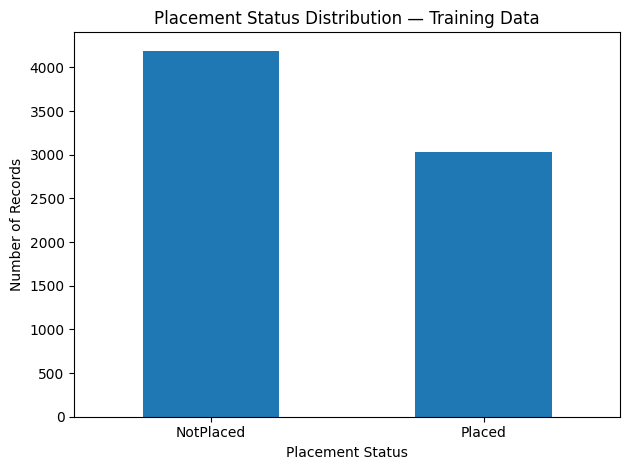

In [6]:
if TARGET not in train_df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")

counts = train_df[TARGET].value_counts(dropna=False)
display(counts.to_frame("Number of records"))
display((train_df[TARGET].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Percentage"))

counts.plot(kind="bar")
plt.title("Placement Status Distribution — Training Data")
plt.xlabel("Placement Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Explore numerical features

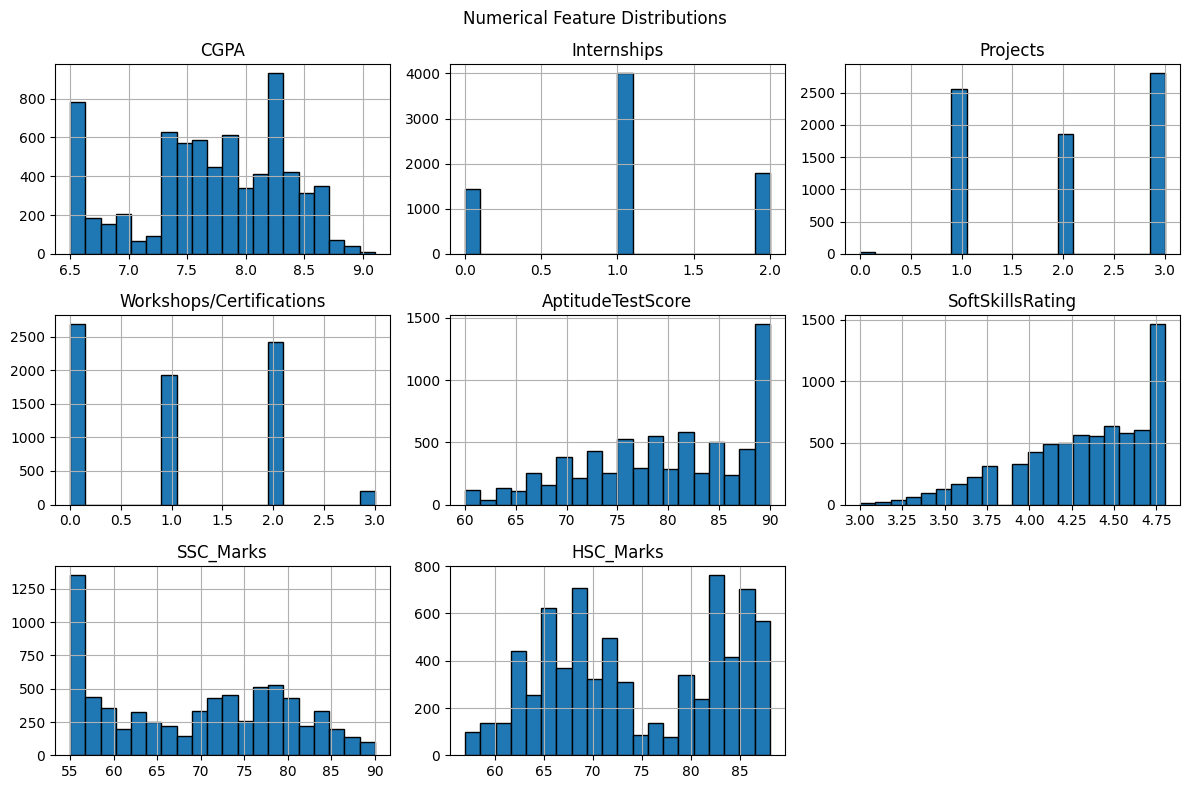

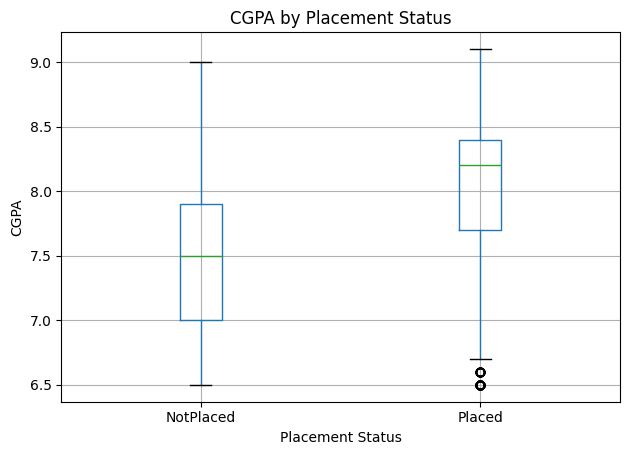

PlacementStatus,NotPlaced,Placed
CGPA,7.470069,8.021372
Internships,0.895302,1.261544
Projects,1.674934,2.513852
Workshops/Certifications,0.742428,1.399077
AptitudeTestScore,75.796566,84.553760
SoftSkillsRating,4.176508,4.531596
SSC_Marks,65.017410,74.954485
HSC_Marks,70.579537,79.827836


In [7]:
numeric_columns = train_df.select_dtypes(include="number").columns.tolist()
if numeric_columns:
    train_df[numeric_columns].hist(figsize=(12, 8), bins=20, edgecolor="black")
    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

if "CGPA" in train_df.columns:
    train_df.boxplot(column="CGPA", by=TARGET)
    plt.title("CGPA by Placement Status")
    plt.suptitle("")
    plt.xlabel("Placement Status")
    plt.ylabel("CGPA")
    plt.tight_layout()
    plt.show()

if numeric_columns:
    display(train_df.groupby(TARGET)[numeric_columns].mean().T)


## 6. Inspect categorical features

In [8]:
categorical_columns = train_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
print("Categorical columns:", categorical_columns)
for col in categorical_columns:
    print(f"\\n{col} value counts:")
    display(train_df[col].value_counts(dropna=False).to_frame("count"))


Categorical columns: ['ExtracurricularActivities', 'PlacementTraining', 'PlacementStatus']
\nExtracurricularActivities value counts:


,count
ExtracurricularActivities,
Yes,4245
No,2980


\nPlacementTraining value counts:


,count
PlacementTraining,
Yes,5270
No,1955


\nPlacementStatus value counts:


,count
PlacementStatus,
NotPlaced,4193
Placed,3032


## 7. Separate input features and target
`PlacementStatus` is the target label and must not be included in the input features.

In [9]:
X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]
X_validation = validation_df.drop(columns=[TARGET])
y_validation = validation_df[TARGET]
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

id_columns = [c for c in X_train.columns
              if c.strip().lower() in {"id", "studentid", "student_id", "rollno", "roll_no"}]
if id_columns:
    X_train = X_train.drop(columns=id_columns)
    X_validation = X_validation.drop(columns=id_columns)
    X_test = X_test.drop(columns=id_columns)
    print("Removed ID columns:", id_columns)

print("Features:", X_train.columns.tolist())
print("Target:", TARGET)


Features: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks']
Target: PlacementStatus


## 8. Define preprocessing pipeline

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created.")


Numeric features: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks']
Categorical features: ['ExtracurricularActivities', 'PlacementTraining']
Preprocessing pipeline created.


## 9. Apply preprocessing


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_validation_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("Preprocessing completed.")


Processed training shape: (7225, 12)
Processed validation shape: (1275, 12)
Processed test shape: (1500, 12)
Preprocessing completed.
